# DMS ranking-resolution paper figures

This notebook composes the curated 49-run HMC figures from tidy tables generated by `summarize.py` and `summarize_mechanisms.py` under `output/hmc/tables`. Each row or curve is one landscape, model specification, and fit artifact; runs fitted to the same landscape remain visually grouped. The legacy 26-run PDZ/TrpB tables remain under `output/tables`. Figure 5 and the Figure 6.1--6.3 renderer comparison are temporary exploratory views and are not yet part of the manuscript outline.

In [3]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

HERE = Path.cwd()
if (HERE / "examples" / "paper" / "figures.py").is_file():
    HERE = HERE / "examples" / "paper"
if not (HERE / "figures.py").is_file():
    raise FileNotFoundError(
        "Run this notebook from the repository or examples/paper directory."
    )
sys.path.insert(0, str(HERE))

import figures

importlib.reload(figures)
from figures import (
    figure_count_rank_uncertainty_by_analysis,
    figure_count_score_uncertainty_by_analysis,
    figure_count_uncertainty_datashader,
    figure_count_uncertainty_hexbin,
    figure_count_uncertainty_scatter,
    figure_fitness_uncertainty_by_analysis,
    figure_functionality_distributions,
    figure_rank_space_sensitivity,
    figure_rank_uncertainty,
    figure_ranking_mechanisms,
    figure_reported_order,
    figure_top_k_stability,
    load_functionality_scores,
    load_mechanism_tables,
    load_tables,
    save_figure,
    set_paper_style,
)

TABLE_DIR = HERE / "output" / "hmc" / "tables"
FIGURE_DIR = HERE / "output" / "hmc" / "figures"
MAIN_K = 100
REPRESENTATIVE_IDS = (
    "pdz__pdz-cis__hmc__lomax-exponential__small-clean-3",
    "trpb__trpb-libd__hmc__gamma-exponential__small-clean-21",
    "nuc__nuc-g1__hmc__exponential__small-clean-55",
)

set_paper_style()
tables = load_tables(TABLE_DIR)
inventory = tables["inventory"].sort_values("analysis_order")
reference_diagnostics = pd.read_csv(TABLE_DIR / "reference_diagnostics.csv")
reference_category_sensitivity = pd.read_csv(
    TABLE_DIR / "reference_category_sensitivity.csv"
)
mechanism_diagnostics = pd.read_csv(TABLE_DIR / "mechanism_diagnostics.csv")
display(inventory)

,analysis_order,analysis_id,protein_family,landscape,inference_method,model_spec,fit_id,job_id,artifact_kind,artifact_validation_status,...,score,n_samples,n_variants,n_fitted_variants,n_excluded_from_ranking,retained_k,tracked_reported_top_n,tracked_model_top_n,artifact_status,warnings
0,0,pdz__pdz-trans-1__hmc__exponential-exponential...,pdz,pdz-trans-1,hmc,exponential-exponential,large-clean_82,82,raw_hmc,validated,...,log_mean_growth,16000,109376,109376,0,1000,1000,100,validated,[]
1,1,pdz__pdz-trans-1__hmc__gamma-exponential__larg...,pdz,pdz-trans-1,hmc,gamma-exponential,large-clean_84,84,diagnosed_hmc,validated,...,log_mean_growth,16000,109376,109376,0,1000,1000,100,validated,[]
2,2,pdz__pdz-trans-2__hmc__exponential-exponential...,pdz,pdz-trans-2,hmc,exponential-exponential,large-clean_88,88,diagnosed_hmc,validated,...,log_mean_growth,16000,142251,142251,0,1000,1000,100,validated,[]
3,3,pdz__pdz-trans-2__hmc__gamma-sigmoid__large-cl...,pdz,pdz-trans-2,hmc,gamma-sigmoid,large-clean_93,93,diagnosed_hmc,validated,...,log_mean_growth,16000,142251,142251,0,1000,1000,100,validated,[]
4,4,pdz__pdz-cis__hmc__exponential-exponential__sm...,pdz,pdz-cis,hmc,exponential-exponential,small-clean_1,1,diagnosed_hmc,validated,...,log_mean_growth,16000,9475,9475,0,1000,1000,100,validated,[]
5,5,pdz__pdz-cis__hmc__lomax-exponential__small-cl...,pdz,pdz-cis,hmc,lomax-exponential,small-clean_3,3,diagnosed_hmc,validated,...,log_mean_growth,16000,9475,9475,0,1000,1000,100,validated,[]
6,6,pdz__pdz-cis__hmc__exponential-sigmoid__small-...,pdz,pdz-cis,hmc,exponential-sigmoid,small-clean_4,4,diagnosed_hmc,validated,...,log_mean_growth,16000,9475,9475,0,1000,1000,100,validated,[]
7,7,pdz__pdz-cript-c__hmc__exponential-exponential...,pdz,pdz-cript-c,hmc,exponential-exponential,large-clean_70,70,diagnosed_hmc,validated,...,log_mean_growth,16000,117723,117723,0,1000,1000,100,validated,[]
8,8,pdz__pdz-cript-c__hmc__lomax-exponential__larg...,pdz,pdz-cript-c,hmc,lomax-exponential,large-clean_71,71,raw_hmc,validated,...,log_mean_growth,24000,117723,117723,0,1000,1000,100,validated,[]
9,9,pdz__pdz-cript-c__hmc__gamma-exponential__larg...,pdz,pdz-cript-c,hmc,gamma-exponential,large-clean_72,72,raw_hmc,validated,...,log_mean_growth,24000,117723,117723,0,1000,1000,100,validated,[]


## Figure 1: Reported ordering

Panels (a)--(d) show where each published top-100 rank falls in its sampled rank distribution for an example, PDZ, TrpB, and NucB. Panel (e) retains the directional ECDF-to-uniform area. Panel (f) adds the more direct Spearman correlation between reported rank and posterior-median sampled rank; positive values mean concordant ordering and negative values would indicate reversal.

For NucB jobs 55, 56, 57, 58, 59, 61, and 62, direct top-100 rank concordance is 0.376, 0.395, 0.609, 0.594, 0.584, 0.334, and 0.333. All values are positive. The later-generation disagreement is therefore not a reversed ranking. NucB compares an all-gate latent fluorescence model with a generation-specific highest-gate enrichment factor, so this is agreement with a gate-specific assay proxy rather than an internal-stability measure.

In [ ]:
figure_1 = figure_reported_order(
    tables,
    cohort_top_n=MAIN_K,
    example_id=REPRESENTATIVE_IDS[0],
)
display(figure_1)
save_figure(figure_1, FIGURE_DIR, "figure1_reported_order")
plt.close(figure_1)

## Figure 2: Rank uncertainty

The first row contains one representative analysis per protein family and shows median-score reference ranks 1–50 in raw rank positions. Each row label begins with its median-score reference rank, followed by the less important variant name. The pale line is the 5th–95th percentile sampled-rank interval, the blue circle is the median sampled rank, and the green diamond is the published rank. The two lower panels summarize all runs: rank-interval widths among each run's reference top 100, and the fraction whose 95th-percentile sampled rank is greater than 100.

In [ ]:
figure_2 = figure_rank_uncertainty(
    tables,
    representative_ids=REPRESENTATIVE_IDS,
    main_k=MAIN_K,
)
display(figure_2)
save_figure(figure_2, FIGURE_DIR, 'figure2_rank_uncertainty')
plt.close(figure_2)

## Figure 3: Top-K decision stability

The top row contains one representative analysis per protein family and shows median-score reference ranks 91--100 plus the ten strongest outside challengers. Every label begins with median-score reference rank. The bottom row evaluates each family at `K = 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000`. Blue compares two sampled top-K sets, orange compares sampled top-K with the median-score reference top-K, and green compares sampled top-K with the published top-K. Thin curves are individual analysis runs; thick curves first combine models within each landscape and then take the median across landscapes.

For NucB, the published top-100 comparator is the generation-specific highest-gate enrichment factor. Correcting candidate eligibility leaves the model/reported top-100 intersections unchanged at 75, 75, 80, 79, 68, 36, and 35 across jobs 55, 56, 57, 58, 59, 61, and 62; overlap with the reversed EF bottom 100 is zero in every run. Thus the lower G4 agreement is not caused by source controls or score direction. It reflects the difference between an all-gate fitted score and the increasingly extreme single-gate proxy.

In [ ]:
figure_3 = figure_top_k_stability(
    tables,
    representative_ids=REPRESENTATIVE_IDS,
    main_k=MAIN_K,
)
display(figure_3)
save_figure(figure_3, FIGURE_DIR, 'figure3_top_k_stability')
plt.close(figure_3)

## Mechanism-table boundary

Figures 1--3 use the compact stability bundles directly. Figures 4--10 use the completed mechanism tables because they additionally require posterior medians for every ranking-eligible candidate and complete score/rank trajectories for challengers identified after top-100 inclusion probabilities were known. This was a recovery pass over existing HMC output, not a second fit or a second uncertainty analysis. All 49 mechanism caches are complete and validated. NucB source controls remain on the fitted posterior axis for alignment but are absent from every mechanism cohort.

## Figure 4: From experimental support to ranking resolution

For variant $i$, let the normalized central 90% score width be

$$
U_i=\frac{Q_{0.95}(z_i)-Q_{0.05}(z_i)}{S_{\mathrm{run}}},
$$

where $S_{\mathrm{run}}$ is the IQR of posterior-median scores among the model-reference top 1,000. Let

$$
W_i^R=Q_{0.95}(R_i)-Q_{0.05}(R_i)
$$

be its sampled-rank interval width. The primary cohort is the model-reference top 100 plus outside variants with at least 1% posterior top-100 inclusion probability. It contains 24,999 run-variant rows across 49 analyses and 18 landscapes.

Panel (a) relates within-run input-support deciles to $U_i$. Panel (b) relates within-run score-uncertainty deciles to $W_i^R$. Panels (c) and (d) compare two same-run neighborhoods with similar focal score uncertainty but different local median-score spacing. Thin curves are analysis runs; bold curves first aggregate models within landscape and then landscapes within family. These are descriptive, model-conditional associations, not estimates of the causal effect of adding reads.

In [ ]:
mechanism_tables = load_mechanism_tables(TABLE_DIR)
figure_4 = figure_ranking_mechanisms(mechanism_tables)
display(figure_4)
save_figure(figure_4, FIGURE_DIR, "figure4_ranking_mechanisms")
plt.close(figure_4)

## Figure 5: Temporary rank-space sensitivity view

This sensitivity view shows the Figure 4 relationships directly in rank positions. Panel (a) bins the primary cohort by within-run input support and plots median central 90% sampled-rank width. Panel (b) bins by raw central 90% score width and again plots rank width. Panels (c) and (d) compare deterministic ten-variant windows with relatively separated versus strongly overlapping sampled-rank intervals.

From input-support decile 1 to 10, the landscape-weighted median rank width changes from 21,445 to 20,885 for PDZ, 6,287 to 46 for TrpB, and 80 to 47 for NucB. The highest-support decile has smaller median rank width in 46 of 49 runs: 11/14 PDZ, 28/28 TrpB, and 7/7 NucB. The figure remains descriptive; it does not substitute for count downsampling and refitting.

In [ ]:
figure_5 = figure_rank_space_sensitivity(mechanism_tables)
display(figure_5)
save_figure(figure_5, FIGURE_DIR, "figure5_rank_space_sensitivity")
plt.close(figure_5)

## Figures 6.1–6.3: Variant-level count support and fitted uncertainty

These three exploratory figures display the same relationships with standard scatter, Datashader, and hexagonal-bin rendering. The inputs are all 57,773 tracked run–variant rows from 49 analyses and 18 landscapes. They include variants with exact score/rank trajectories in `mechanism_variants.csv`, not every raw-table variant. A biological variant can appear once per fitted model, so rows are not independent biological replicates.

The four panels compare observed input or output count with normalized score or rank uncertainty. Counts use $\log_{10}(n+1)$ so zeros are retained. Color identifies landscape; marker shape identifies model family where individual points are visible. Dark lines are pooled descriptive least-squares trends, not landscape-balanced estimates or inferential regressions.

In [ ]:
figure_6_1 = figure_count_uncertainty_scatter(mechanism_tables)
display(figure_6_1)
save_figure(
    figure_6_1,
    FIGURE_DIR,
    "figure6_1_count_uncertainty_scatter",
)
plt.close(figure_6_1)

### Figure 6.2: Datashader density

In [ ]:
figure_6_2 = figure_count_uncertainty_datashader(mechanism_tables)
display(figure_6_2)
save_figure(
    figure_6_2,
    FIGURE_DIR,
    "figure6_2_count_uncertainty_datashader",
)
plt.close(figure_6_2)

### Figure 6.3: Hexagonal-bin density

In [ ]:
figure_6_3 = figure_count_uncertainty_hexbin(mechanism_tables)
display(figure_6_3)
save_figure(
    figure_6_3,
    FIGURE_DIR,
    "figure6_3_count_uncertainty_hexbin",
)
plt.close(figure_6_3)

## Figures 7.1–7.2: Count support and uncertainty within each analysis

These temporary figures separate the pooled Figure 6 relationships into one row per analysis run. Each row uses every tracked run–variant row for that analysis, with input count on the left and output count on the right. Counts retain zero through $\log_{10}(n+1)$.

Figures **7.1.pdz**, **7.1.trpb**, and **7.1.nucb** plot relative score uncertainty,

$$
\frac{Q_{0.95}(z_i)-Q_{0.05}(z_i)}{S_{\mathrm{run}}}.
$$

Figures **7.2.pdz**, **7.2.trpb**, and **7.2.nucb** plot relative rank uncertainty,

$$
\frac{Q_{0.95}(R_i)-Q_{0.05}(R_i)}{N_{\mathrm{candidates}}}.
$$

All rows within one figure share the same input-count scale, output-count scale, and uncertainty scale, so patterns can be compared directly across analyses for that protein family. Each dark line is fit only to the variants in that row and panel. It is a descriptive least-squares line in the plotted coordinates, not an inferential or causal estimate. Color identifies landscape and marker shape identifies model family; the analysis label is also printed above the left panel of every row.

### Figure 7.1.pdz: Relative score uncertainty by PDZ analysis

In [ ]:
figure_7_1_pdz = figure_count_score_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_7_1_pdz)
save_figure(
    figure_7_1_pdz,
    FIGURE_DIR,
    "figure7_1_pdz_by_analysis",
)
plt.close(figure_7_1_pdz)

### Figure 7.1.trpb: Relative score uncertainty by TrpB analysis

In [ ]:
figure_7_1_trpb = figure_count_score_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_7_1_trpb)
save_figure(
    figure_7_1_trpb,
    FIGURE_DIR,
    "figure7_1_trpb_by_analysis",
)
plt.close(figure_7_1_trpb)

### Figure 7.1.nucb: Relative score uncertainty by NucB analysis

In [ ]:
figure_7_1_nuc = figure_count_score_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_7_1_nuc)
save_figure(
    figure_7_1_nuc,
    FIGURE_DIR,
    "figure7_1_nucb_by_analysis",
)
plt.close(figure_7_1_nuc)

### Figure 7.2.pdz: Relative rank uncertainty by PDZ analysis

In [ ]:
figure_7_2_pdz = figure_count_rank_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_7_2_pdz)
save_figure(
    figure_7_2_pdz,
    FIGURE_DIR,
    "figure7_2_pdz_by_analysis",
)
plt.close(figure_7_2_pdz)

### Figure 7.2.trpb: Relative rank uncertainty by TrpB analysis

In [ ]:
figure_7_2_trpb = figure_count_rank_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_7_2_trpb)
save_figure(
    figure_7_2_trpb,
    FIGURE_DIR,
    "figure7_2_trpb_by_analysis",
)
plt.close(figure_7_2_trpb)

### Figure 7.2.nucb: Relative rank uncertainty by NucB analysis

In [ ]:
figure_7_2_nuc = figure_count_rank_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_7_2_nuc)
save_figure(
    figure_7_2_nuc,
    FIGURE_DIR,
    "figure7_2_nucb_by_analysis",
)
plt.close(figure_7_2_nuc)

## Figure 8: Median fitted-score geometry

This exploratory view treats the distribution of fitted scores as one aspect of landscape functionality. For candidate $i$, let

$$
m_i = Q_{0.50}(z_i \mid D),
$$

where $z_i$ is the family's primary latent score: `log_mean_growth` for PDZ and TrpB, and modeled log fluorescence for NucB. Each panel is one experimental landscape. Within a panel, every available model is shown as a Gaussian KDE of $m_i$ over all ranking-eligible candidates, using SciPy's Scott-rule bandwidth. The model-specific vertical line is the score at fixed median-score reference rank 100; that model's top 100 lies to its right. Curves and cutoffs use the same model style. All panels within one protein-family figure share score and density limits.

This figure shows between-candidate geometry in each fitted ordering; it does not show within-candidate posterior uncertainty. The term *functionality* is operational here: these are model-conditional score distributions, not experimentally validated binary functional/nonfunctional classifications.

### Figure 8.1: PDZ landscapes

In [ ]:
functionality_scores = load_functionality_scores(TABLE_DIR)
figure_8_1_pdz = figure_functionality_distributions(
    inventory,
    functionality_scores,
    protein_family="pdz",
    top_k=MAIN_K,
)
display(figure_8_1_pdz)
save_figure(
    figure_8_1_pdz,
    FIGURE_DIR,
    "figure8_pdz_functionality",
)
plt.close(figure_8_1_pdz)

### Figure 8.2: TrpB landscapes

In [ ]:
figure_8_2_trpb = figure_functionality_distributions(
    inventory,
    functionality_scores,
    protein_family="trpb",
    top_k=MAIN_K,
)
display(figure_8_2_trpb)
save_figure(
    figure_8_2_trpb,
    FIGURE_DIR,
    "figure8_trpb_functionality",
)
plt.close(figure_8_2_trpb)

### Figure 8.3: NucB landscapes

In [ ]:
figure_8_3_nuc = figure_functionality_distributions(
    inventory,
    functionality_scores,
    protein_family="nuc",
    top_k=MAIN_K,
)
display(figure_8_3_nuc)
save_figure(
    figure_8_3_nuc,
    FIGURE_DIR,
    "figure8_nucb_functionality",
)
plt.close(figure_8_3_nuc)

## Figure 9: Decision-relative fitness and score uncertainty

For candidate $i$, define

$$
x_i=\frac{m_i-m_{(100)}}{S_{\mathrm{run}}},
\qquad
y_i=\frac{Q_{0.95}(z_i)-Q_{0.05}(z_i)}{S_{\mathrm{run}}},
$$

where $m_i$ is the posterior-median primary score, $m_{(100)}$ is the score at fixed model-reference rank 100, and $S_{\mathrm{run}}$ is the top-1,000 median-score IQR. Thus $x=0$ is the fixed top-100 boundary. Blue filled points are fixed top-100 members; orange open points are outside variants with at least 1% sampled top-100 inclusion probability.

Across the 49 runs, the within-run Spearman association ranges from $-0.961$ to $0.727$ and is negative in 42 runs. It is negative in 13/14 PDZ runs and all 28 TrpB runs, but only 1/7 NucB runs. NucB therefore shows that lower decision-relative score is not universally associated with wider posterior score intervals. The relationship is descriptive and model-conditional; it does not establish that score location causes uncertainty.

### Figure 9.1: PDZ analyses

In [ ]:
figure_9_1_pdz = figure_fitness_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_9_1_pdz)
save_figure(
    figure_9_1_pdz,
    FIGURE_DIR,
    "figure9_pdz_fitness_uncertainty",
)
plt.close(figure_9_1_pdz)

### Figure 9.2: TrpB analyses

In [ ]:
figure_9_2_trpb = figure_fitness_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_9_2_trpb)
save_figure(
    figure_9_2_trpb,
    FIGURE_DIR,
    "figure9_trpb_fitness_uncertainty",
)
plt.close(figure_9_2_trpb)

### Figure 9.3: NucB analyses

In [ ]:
figure_9_3_nuc = figure_fitness_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_9_3_nuc)
save_figure(
    figure_9_3_nuc,
    FIGURE_DIR,
    "figure9_nucb_fitness_uncertainty",
)
plt.close(figure_9_3_nuc)

## Figure 10: Per-analysis summary of why the top 100 is uncertain

Each row is one analysis and uses the same primary cohort as Figure 9. The four columns relate input support, output abundance, and decision margin to normalized score uncertainty and top-100 inclusion probability. Filled blue points are fixed top-100 members; open orange points are outside challengers. Row labels report top-100 instability and challenger count.

Across all 49 runs, the within-run Spearman association between count and score uncertainty remains negative for both input count (range $-0.993$ to $-0.018$) and output count (range $-0.998$ to $-0.037$). The decision-margin association ranges from $-0.961$ to $0.727$ and is negative in 42/49 runs. These values are unchanged in substance by the NucB eligibility correction.

The supporting audit reports these associations separately for model-top-100 members and outside challengers and gives a rank-residual partial Spearman adjusted for input support. Several positive NucB primary-cohort slopes weaken or reverse within the two strata. This is consistent with cohort composition near the decision boundary, not a reversed score direction or failure of the stability analysis. The associations remain descriptive: variants share posterior draws, output abundance is fitness-dependent, and multiple analyses of one landscape share counts.

### Figure 10.1: PDZ analyses

In [ ]:
from figures import figure_summary_why_by_analysis

figure_10_1_pdz = figure_summary_why_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_10_1_pdz)
save_figure(
    figure_10_1_pdz,
    FIGURE_DIR,
    "figure10_pdz_summary_why",
)
plt.close(figure_10_1_pdz)

### Figure 10.2: TrpB analyses

In [ ]:
from figures import figure_summary_why_by_analysis

figure_10_2_trpb = figure_summary_why_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_10_2_trpb)
save_figure(
    figure_10_2_trpb,
    FIGURE_DIR,
    "figure10_trpb_summary_why",
)
plt.close(figure_10_2_trpb)

### Figure 10.3: NucB analyses

In [ ]:
from figures import figure_summary_why_by_analysis

figure_10_3_nuc = figure_summary_why_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_10_3_nuc)
save_figure(
    figure_10_3_nuc,
    FIGURE_DIR,
    "figure10_nucb_summary_why",
)
plt.close(figure_10_3_nuc)

### NucB eligibility and interpretation audit

The source-role correction is intentionally small. The seven NucB model/reported top-100 intersections are unchanged, and no reversed-EF top-100 set overlaps a model top 100. The table below separates the Figure 10 decision-margin association into the displayed primary cohort, fixed model-top-100 members, and outside challengers. `partial_input_adjusted` is a rank-residual partial Spearman adjusted for input support.

In [ ]:
nuc_reference_audit = reference_diagnostics[
    reference_diagnostics["protein_family"].eq("nuc")
][
    [
        "fit_id",
        "n_fitted_variants",
        "n_ranking_candidates",
        "n_excluded_from_ranking",
        "all_finite_spearman",
        "positive_reported_spearman",
        "model_reported_top_k_intersection",
        "model_reversed_reported_top_k_intersection",
    ]
]

nuc_mechanism_audit = mechanism_diagnostics[
    mechanism_diagnostics["protein_family"].eq("nuc")
].pivot(
    index="analysis_id",
    columns="stratum",
    values="decision_margin_vs_score_uncertainty_spearman",
).rename_axis(columns=None).reset_index()
partial = mechanism_diagnostics[
    mechanism_diagnostics["protein_family"].eq("nuc")
    & mechanism_diagnostics["stratum"].eq("primary")
][
    [
        "analysis_id",
        "decision_margin_vs_score_uncertainty_partial_spearman_input_adjusted",
    ]
].rename(
    columns={
        "decision_margin_vs_score_uncertainty_partial_spearman_input_adjusted": (
            "partial_input_adjusted"
        )
    }
)

nuc_mechanism_audit = nuc_mechanism_audit.merge(
    partial,
    on="analysis_id",
    validate="one_to_one",
)
display(nuc_reference_audit)
display(nuc_mechanism_audit)

## Artifact inventory

In [ ]:
display(
    inventory[[
        "analysis_id",
        "n_samples",
        "n_fitted_variants",
        "n_variants",
        "n_excluded_from_ranking",
        "artifact_status",
        "warnings",
    ]]
)

## Figure 11: Joint count support and score uncertainty

Each small corner is one analysis. Within each horizontal block, each column is one landscape and its fitted models are stacked vertically; blocks contain at most three landscapes so the corner panels remain readable. The plotted variant cohort is the median-score top 100, outside variants with at least 1% sampled top-100 inclusion probability, and eligible reported top-1,000 context. Diagonal panels show black KDEs in the displayed coordinates for observed input count, observed output count, and relative posterior score uncertainty. Lower-triangle panels show all three pairwise relationships: tiny gray points are reported-context-only variants, small filled blue circles are median-score top-100 variants, and small hollow orange circles are challengers. Upper-triangle cells report within-analysis Spearman correlations. Counts use $\log_{10}(n+1)$ so zeros are retained. Relative score uncertainty is the 90% posterior score width divided by the run score IQR and is displayed on a log scale. Axis limits are shared within each protein family. These are descriptive, model-conditional associations.

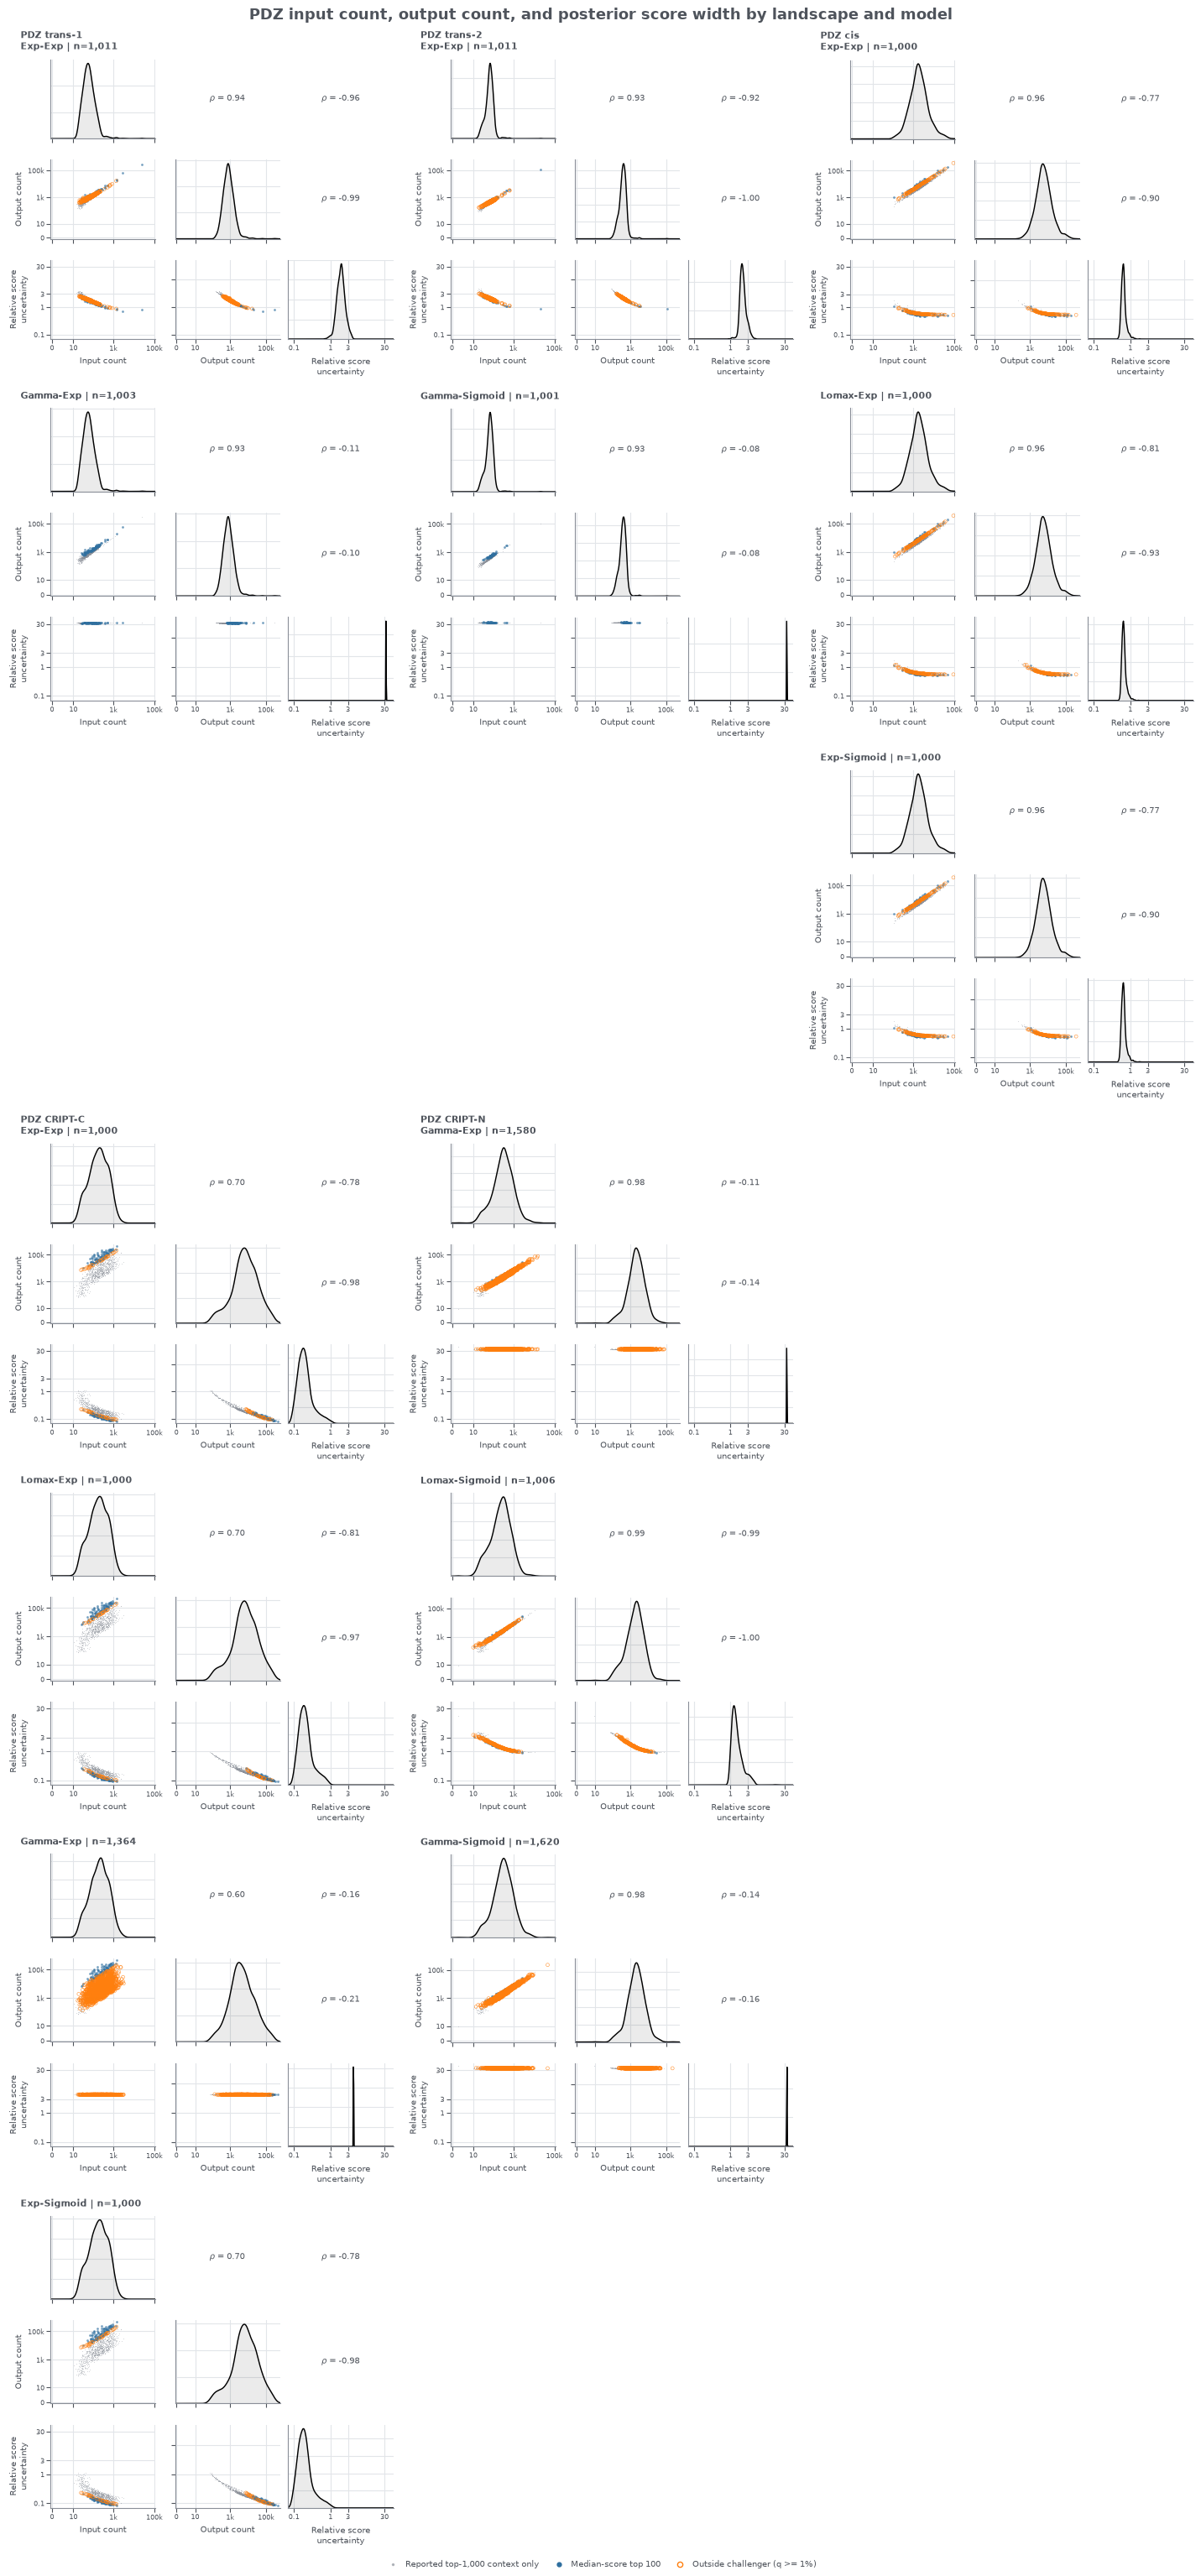

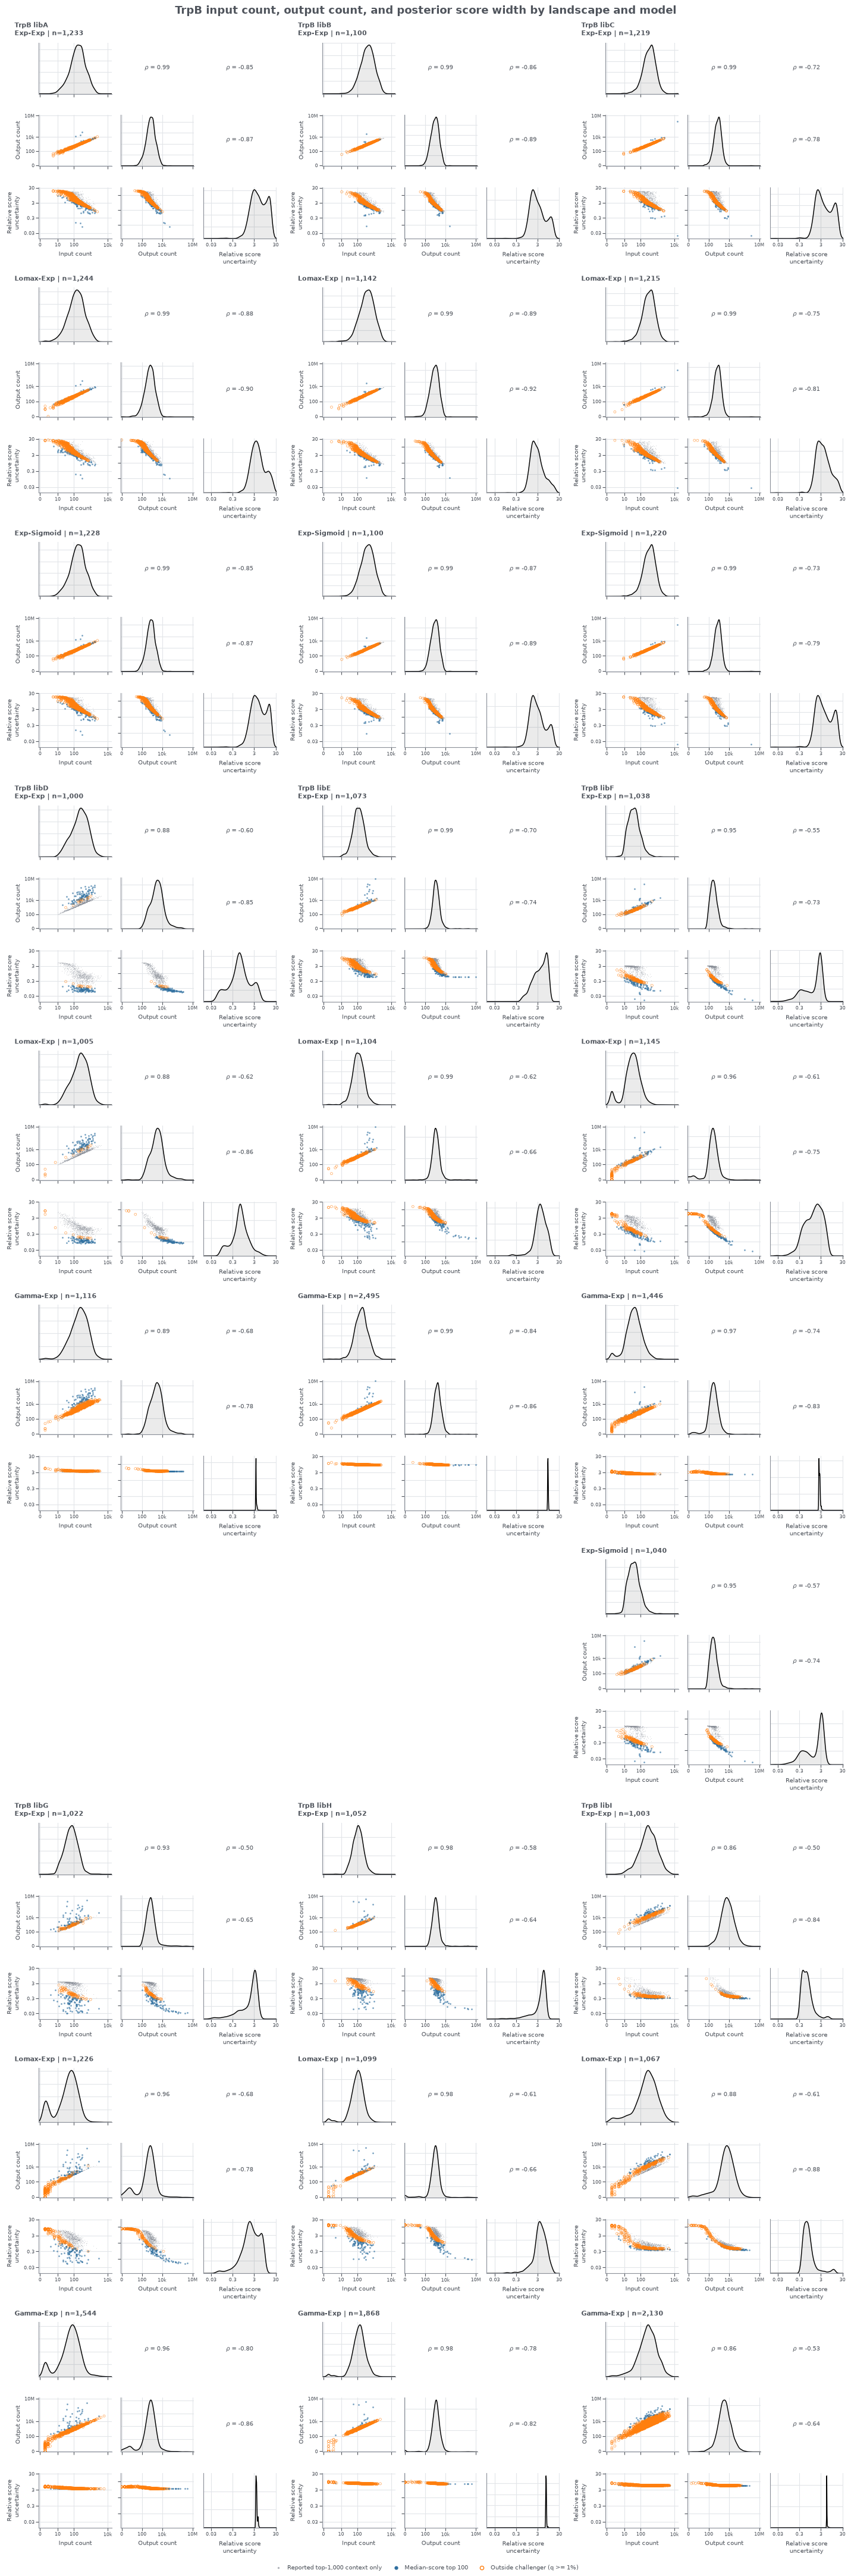

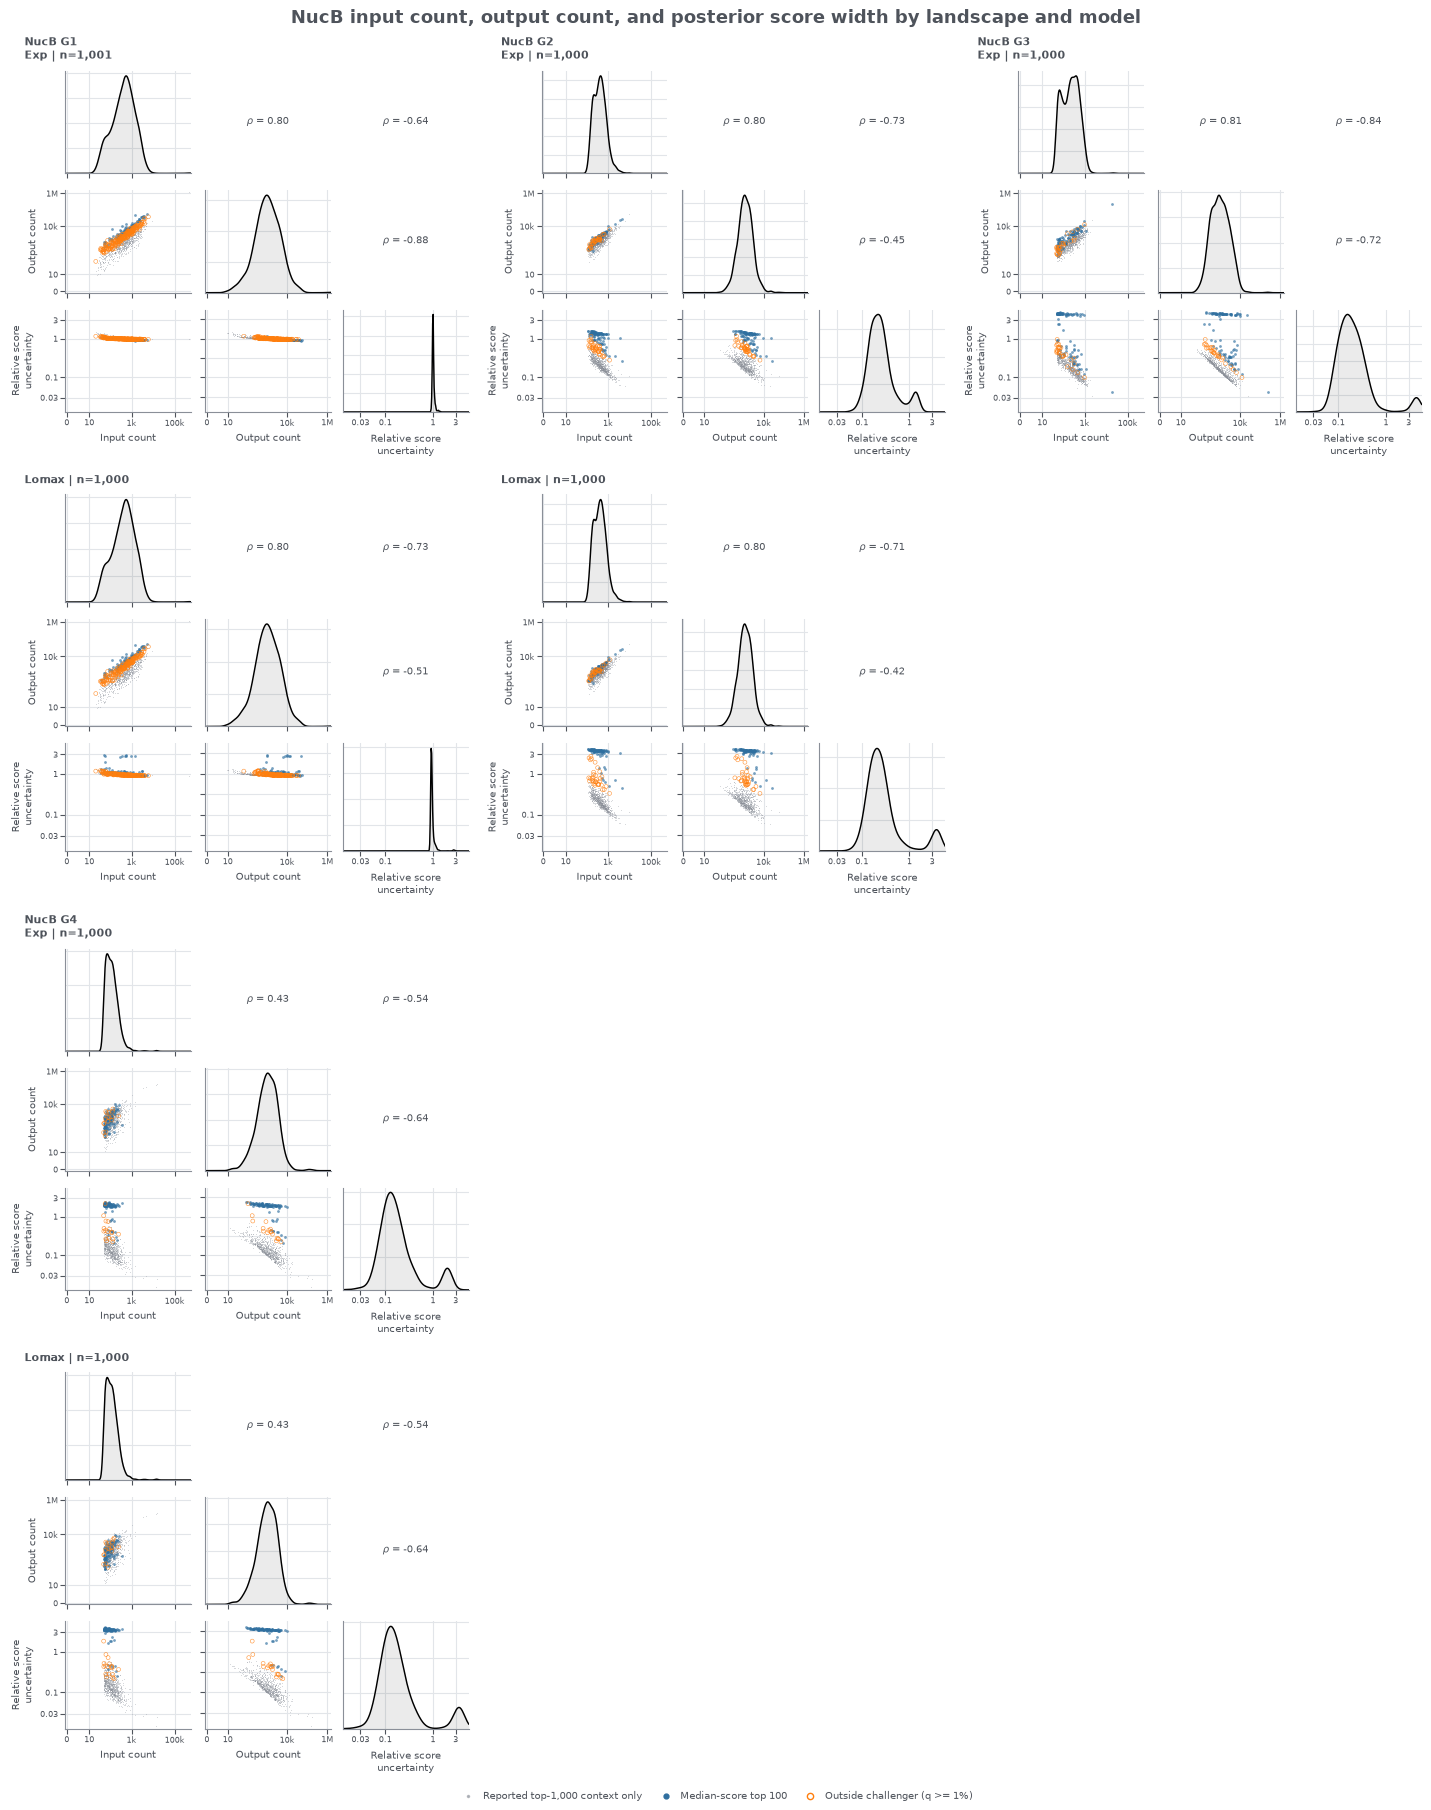

In [4]:
from figures import FAMILY_FILE_STEMS, figure_count_score_corner_by_analysis

figure_11_tables = load_mechanism_tables(TABLE_DIR)
figure_11_families = inventory["protein_family"].drop_duplicates().tolist()
for family in figure_11_families:
    figure_11 = figure_count_score_corner_by_analysis(
        figure_11_tables,
        protein_family=family,
    )
    display(figure_11)
    save_figure(
        figure_11,
        FIGURE_DIR,
        f"figure11_{FAMILY_FILE_STEMS[family]}_count_score_corner",
    )
    plt.close(figure_11)